# Converting a mesh between formats with meshio++ (Octave/MATLAB)

Octave/MATLAB counterpart of [`../r/02_convert_and_inspect.ipynb`](../r/02_convert_and_inspect.ipynb) and
[`../cpp/02_convert_and_inspect.ipynb`](../cpp/02_convert_and_inspect.ipynb). meshio++'s registry dispatches
to any of its 40+ format writers from one table; here we take the bracket geometry, write it to several
formats through `mio.write`, compare sizes, and verify every round trip.

XDMF's data format depends on the build (`MESHIOPLUSPLUS_HAS_HDF5`): HDF5 when the C library has it, inline
XML otherwise. The sizes below were produced with a C library built with HDF5 off, like the R and Julia
notebooks' (see [`README.md`](./README.md)), so XDMF falls back to inline XML.

In [1]:
warning('off', 'Octave:shadowed-function');
addpath(fullfile(pwd, '..', '..', 'bindings', 'octave', 'meshioplusplus', 'inst'));
mio_notebook

meshio++ 18.2.0 (Octave/MATLAB binding)


In [2]:
mesh = mio.read('example.vtu');
tri = mio.cell_block_info(mesh, 1);
tet = mio.cell_block_info(mesh, 2);
fprintf('%d points, %d triangles, %d tetrahedra\n', mio.num_points(mesh), tri.num_cells, tet.num_cells);

52282 points, 58394 triangles, 235014 tetrahedra


## Convert to several formats

In [3]:
tmpdir = tempname();
mkdir(tmpdir);
formats = {'vtu', 'vtk', 'xdmf', 'gmsh', 'ply'};
extensions = {'vtu', 'vtk', 'xdmf', 'msh', 'ply'};
paths = cellfun(@(e) fullfile(tmpdir, ['mesh.' e]), extensions, 'UniformOutput', false);

for k = 1:numel(formats)
    mio.write(mesh, paths{k}, 'format', formats{k});
end

sizes_mb = zeros(1, numel(formats));
for k = 1:numel(formats)
    d = dir(paths{k});
    sizes_mb(k) = d.bytes / 1e6;
    fprintf('%-6s %6.2f MB\n', formats{k}, sizes_mb(k));
end

meshio warning [ply.cpp:490] PLY: writing the extracted skin of the volume cells; 1 pre-existing non-volume cell block(s) dropped (pass skin=false for the legacy behavior).

vtu      4.76 MB
vtk     13.70 MB
xdmf     0.00 MB
gmsh    12.94 MB
ply      1.46 MB


## Compare file sizes

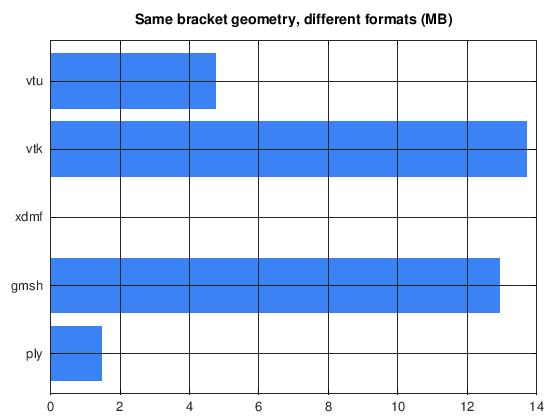

In [4]:
mio_bar_chart(formats, sizes_mb, 'Same bracket geometry, different formats (MB)')

## Round-trip verification

Read every file back and check the point/cell counts survive. `ply` is the expected exception: meshio++'s
PLY writer defaults to writing the extracted, linearized **skin** (triangles only), not the original
triangle+tetra blocks, so its round trip is compared against the skin instead.

In [5]:
n_pts = mio.num_points(mesh);
n_cells = mio.num_cells(mesh);
skin = mio.extract_skin(mesh, 'linearize', true);

for k = 1:numel(formats)
    fmt = formats{k};
    back = mio.read(paths{k}, 'format', fmt);
    bpts = mio.num_points(back);
    bcells = mio.num_cells(back);
    if strcmp(fmt, 'ply')
        expect_pts = mio.num_points(skin);
        expect_cells = mio.num_cells(skin);
    else
        expect_pts = n_pts;
        expect_cells = n_cells;
    end
    if bpts == expect_pts && bcells == expect_cells
        verdict = 'OK  ';
    else
        verdict = 'DIFF';
    end
    fprintf('%s %-6s points=%d cells=%d\n', verdict, fmt, bpts, bcells);
end

OK   vtu    points=52282 cells=293408


OK   vtk    points=52282 cells=293408


OK   xdmf   points=52282 cells=293408


OK   gmsh   points=52282 cells=293408


OK   ply    points=29151 cells=58394


The PLY file holds the skin: draw what came back. The rasterizer needs no particular format -- any mesh a
reader returns can be drawn.

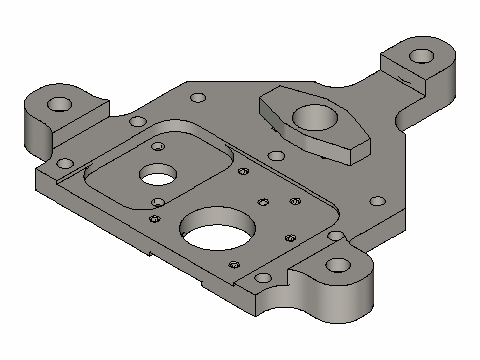

In [6]:
ply_back = mio.read(paths{end}, 'format', 'ply');
render(ply_back)

Every format round-trips the geometry it is capable of carrying — the same registry, the same
writers, the same guarantees as the C++/Python/Fortran/Julia/R bindings; only the calling convention
differs.